# 07 - Final evaluation and interpretation

Goal: evaluate the chosen model once on the test set, look at its errors, and see which features it uses. The model and its settings were fixed in notebook 06. Nothing is changed after seeing the test results.

## 1. Final model and test predictions

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # to import src from the notebooks folder

import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error
from src import config, features as ft, metrics, pipelines as pp, plots as pl

pd.set_option("display.max_columns", 50, "display.width", 200)
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

TARGET, FEATURES, RS = config.TARGET, config.FEATURES, config.RANDOM_STATE
t = ft.load_table()
assert t.shape == (24905, 25)    # same table as notebook 06
fit_data = t[t["split"] != "test"]    # train + validation
test = t[t["split"] == "test"]
y = test[TARGET].to_numpy()

final = pp.make_final_pipeline()
final.fit(fit_data[FEATURES], fit_data[TARGET])
pred = np.clip(final.predict(test[FEATURES]), 0, None)
base_pred = np.full(len(test), fit_data[TARGET].median())    # baseline: median of the same data

config.MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(final, config.MODELS_DIR / "final_model.joblib")
print("fitted on", len(fit_data), "incidents (up to", fit_data["opened_at"].max(), ") | test:", len(test), "incidents")

pandas 2.3.3 | scikit-learn 1.7.2
fitted on 19924 incidents (up to 2016-05-10 22:27:00 ) | test: 4981 incidents


The model is refitted on train + validation, the most recent incidents before the test, in the same regime as the test (notebook 05). The baseline predicts the median of the same data.

## 2. Test metrics

In [2]:
rows = {}
for label, p in {"Baseline (median)": base_pred, "HistGradientBoosting (log target)": pred}.items():
    rows[label] = {**metrics.regression_metrics(y, p), "mean error": (p - y).mean()}
final_metrics = pd.DataFrame(rows).T.round(2)
final_metrics.to_csv(config.TABLES_DIR / "final_test_metrics.csv")
display(final_metrics)

# how sure is the gain? bootstrap on the test incidents (1000 resamples)
err_model, err_base = np.abs(y - pred), np.abs(y - base_pred)
idx = np.random.default_rng(RS).integers(0, len(test), (1000, len(test)))
mae_model, gain = err_model[idx].mean(axis=1), err_base[idx].mean(axis=1) - err_model[idx].mean(axis=1)
print("MAE of the model, 95% interval:", np.percentile(mae_model, [2.5, 97.5]).round(1))
print("MAE reduction against the baseline, 95% interval:", np.percentile(gain, [2.5, 97.5]).round(1))

,MAE,RMSE,RMSLE,mean error
Baseline (median),132.49,454.66,2.44,-109.47
HistGradientBoosting (log target),117.24,419.16,1.74,-89.06


MAE of the model, 95% interval: [106.2 129.7]
MAE reduction against the baseline, 95% interval: [12.8 18. ]


On the test set (4,981 incidents), the model achieves an MAE of 117.2 h against 132.5 h for the baseline (11.5% better). RMSE and RMSLE also improve. The MAE reduction is confirmed by the 95% confidence interval (12.8 to 18.0 h).

The improvement is similar to validation, but errors remain large: around 117 h (almost 5 days), compared to a median resolution time of only 2.6 h.

## 3. Actual vs predicted and errors

over-estimated: 64.4% | mean error: -89.1 | median error: 0.7


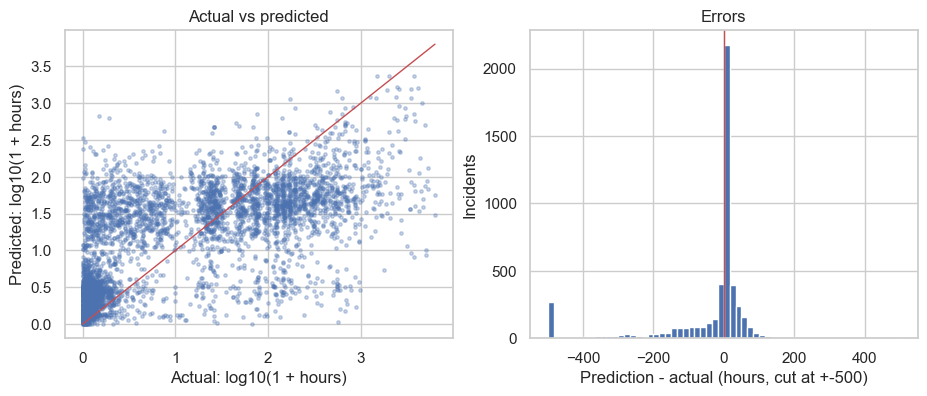

In [3]:
pl.plot_actual_vs_predicted(y, pred)
resid = pred - y
print("over-estimated:", f"{(resid > 0).mean():.1%}", "| mean error:", round(resid.mean(), 1), "| median error:", round(np.median(resid), 1))

The scatter plot shows that predictions are generally good for short incidents, but not for long ones. For incidents over 100 h, predictions stay mostly between 30 and 100 h.

The error histogram is concentrated around zero, but has a long tail of under-estimated incidents. Around 260 incidents are under-estimated by at least 500 h. Although 64.4% of predictions are slightly too high, the mean error is -89.1 h because of the very long incidents.

## 4. Errors by group

In [4]:
def error_table(by):
    """Number of incidents, MAE of the baseline and of the model, and mean error, for each group."""
    d = pd.DataFrame({"by": by.reset_index(drop=True), "base": err_base, "model": err_model, "err": pred - y})
    out = d.groupby("by", observed=True).agg(n=("model", "size"), MAE_baseline=("base", "mean"),
                                             MAE_model=("model", "mean"), mean_error=("err", "mean")).round(1)
    out.index.name = by.name
    return out


duration = pd.cut(test[TARGET], [-0.1, 1, 24, np.inf], labels=["under 1 h", "1 to 24 h", "over 24 h"]).rename("real duration")
by_duration = error_table(duration)
by_priority = error_table(test["priority"])
by_category = error_table(test["category"]).sort_values("n", ascending=False).head(10)

for table, name in [(by_duration, "duration"), (by_priority, "priority"), (by_category, "category")]:
    table.to_csv(config.TABLES_DIR / f"test_errors_by_{name}.csv")
    display(table)

,n,MAE_baseline,MAE_model,mean_error
real duration,,,,
under 1 h,2159,20.4,8.2,8.2
1 to 24 h,1027,13.1,31.8,29.6
over 24 h,1795,335.6,297.3,-273.9


,n,MAE_baseline,MAE_model,mean_error
priority,,,,
1 - Critical,35,138.3,140.2,-97.8
2 - High,61,84.3,91.4,-41.9
3 - Moderate,4764,135.0,119.3,-91.1
4 - Low,121,55.2,43.5,-30.2


,n,MAE_baseline,MAE_model,mean_error
category,,,,
Category 42,909,68.3,56.6,-45.6
Category 26,642,54.5,41.1,-34.0
Category 46,488,234.0,228.2,-155.7
Category 53,414,143.2,133.1,-108.6
Category 32,294,61.1,49.3,-46.0
Category 57,282,129.0,124.9,-99.1
Category 37,257,107.9,102.7,-80.1
Category 9,253,115.1,107.3,-67.5
Category 23,220,132.8,129.9,-103.5


The results are similar to validation.

- **Under 1 h:** MAE 8.2 h vs 20.4 h for the baseline. This is where the model works best.
- **1 to 24 h:** MAE 31.8 h vs 13.1 h. The model over-estimates by 29.6 h on average.
- **Over 24 h:** MAE 297.3 h vs 335.6 h. These incidents account for about 91% of the total error.

**By priority:** The model performs better for Moderate and Low incidents, but worse for Critical and High incidents. These last two groups are small, so the results should be interpreted carefully.

**By category:** The model beats the baseline in the 10 largest categories. Category 46 has the worst results (MAE 228.2 h), while Categories 20 and 26 have the lowest errors.

## 5. Feature importance

I use permutation importance on the test set. I shuffle each feature and measure how much the MAE increases. A bigger increase means the feature is more important to the model. This shows which features the model uses, not what causes longer resolution times.

Some features are related, so I also shuffle them together: `priority`, `impact`, `urgency` and `hour`, `weekday`.

,mean,std
assignment_group,14.06,0.22
sys_created_by,8.74,0.84
category,3.54,0.25
subcategory,1.70,0.24
u_symptom,0.92,0.28
opened_by,0.45,0.21
location,0.35,0.27
hour,0.14,0.18
impact,0.03,0.03
weekday,0.01,0.13


,increase in MAE (hours)
priority + impact + urgency,0.08
hour + weekday,0.20


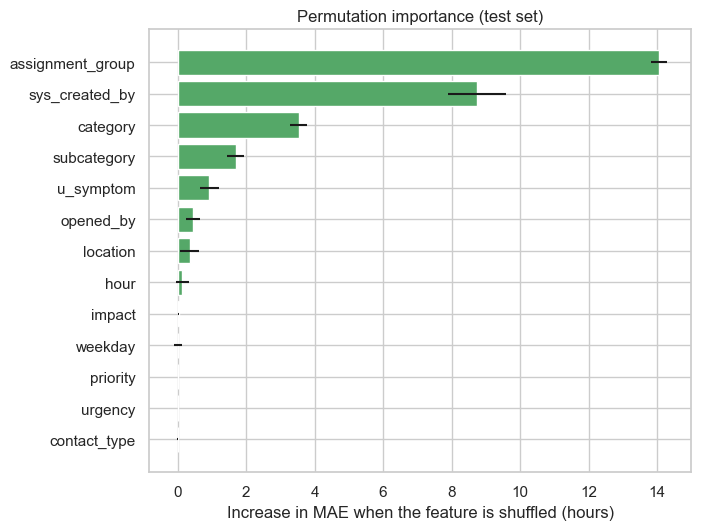

In [5]:
imp = permutation_importance(final, test[FEATURES], test[TARGET], scoring="neg_mean_absolute_error",
                             n_repeats=5, random_state=RS, n_jobs=-1)
importance = pd.DataFrame({"mean": imp.importances_mean, "std": imp.importances_std}, index=FEATURES)
importance.round(2).sort_values("mean", ascending=False).to_csv(config.TABLES_DIR / "permutation_importance.csv")
pl.plot_importance(importance)
display(importance.sort_values("mean", ascending=False).round(2))


def shuffle_group(cols, repeats=5):
    """Increase in MAE when several columns are shuffled together (same new order for all of them)."""
    rng = np.random.default_rng(RS)
    reference = mean_absolute_error(y, final.predict(test[FEATURES]))
    scores = []
    for _ in range(repeats):
        X = test[FEATURES].copy()
        X[cols] = X[cols].iloc[rng.permutation(len(X))].to_numpy()
        scores.append(mean_absolute_error(y, final.predict(X)) - reference)
    return round(float(np.mean(scores)), 2)


pd.Series({"priority + impact + urgency": shuffle_group(["priority", "impact", "urgency"]),
           "hour + weekday": shuffle_group(["hour", "weekday"])}, name="increase in MAE (hours)").to_frame()

The most important features are `assignment_group` (14.1 h) and `sys_created_by` (8.7 h). `category` and `subcategory` have a smaller impact. The others are close to zero.

- **Priority, impact, urgency:** almost no effect when shuffled together (0.08 h).
- **Hour and weekday:** also very little effect (0.20 h).
- **`sys_created_by`:** its importance may be overstated because other features can replace it when removed before training.

These results show which features the model uses, not what causes longer resolution times. I still cannot explain the role of `sys_created_by`.

## Summary and limits

**Summary**
- Test MAE is 117.2 h against 132.5 h for the baseline (-11.5%).
- The model predicts short incidents better than long ones. Incidents over 24 h account for 91% of the error.
- The main features are `assignment_group` and `sys_created_by`.

**Limits**
- Long incidents are underestimated, while 1–24 h incidents are overestimated.
- No improvement for Critical and High priority incidents.
- The data covers only one company and a short period (February–May 2016).
- Important information is missing, such as incident descriptions and team workload.
- 13 incidents without a `Resolved` status were excluded.
- Feature importance shows correlation, not causation.
- Predictions are estimates, not guaranteed resolution times.